In [ ]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, classification_report,log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn import metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
# pip install mord
#from mord import LogisticIT
import matplotlib.pylab as plt
import seaborn as sns
!pip install dmba
from dmba import classificationSummary, gainsChart, liftChart
from dmba.metric import AIC_score
#Import math Library
import math

In [ ]:
# Mounting the Google Drive, the file path might be different for each of us
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Loading data

In [ ]:
# Load dataset
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv')
SBA_df.head()

,UrbanRural,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession
0,0,0,60000.0,0,48000.0,Below 10 years,0
1,0,0,40000.0,0,32000.0,Below 10 years,0
2,0,0,287000.0,0,215250.0,Above 10 years,0
3,0,0,517000.0,0,387750.0,Below 10 years,0
4,0,0,45000.0,0,36000.0,Below 10 years,0


In [ ]:
SBA_df2 = SBA_df.copy()
SBA_df2['Term_Category'] = SBA_df2['Term_Category'].astype('category')
SBA_df2['UrbanRural'] = SBA_df2['UrbanRural'].astype('category')
SBA_df2['RevLineCr'] = SBA_df2['RevLineCr'].astype('category')
SBA_df2['Recession'] = SBA_df2['Recession'].astype('category')


In [ ]:
SBA_df2.dtypes

,0
UrbanRural,category
RevLineCr,category
DisbursementGross,float64
MIS_Status,int64
SBA_Appv,float64
Term_Category,category
Recession,category


In [ ]:
SBA_df2.columns

Index(['UrbanRural', 'RevLineCr', 'DisbursementGross', 'MIS_Status',
       'SBA_Appv', 'Term_Category', 'Recession'],
      dtype='object')

In [ ]:
SBA_df2.UrbanRural.value_counts()

,count
UrbanRural,
1,299084
0,109516
2,64929


# Create dummy variables

In [ ]:
# Dummy variables
SBA_df3 = pd.get_dummies(SBA_df2, columns=['UrbanRural'], drop_first=False, prefix_sep='_', dtype=int)
SBA_df3

,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession,UrbanRural_0,UrbanRural_1,UrbanRural_2
0,0,60000.0,0,48000.0,Below 10 years,0,1,0,0
1,0,40000.0,0,32000.0,Below 10 years,0,1,0,0
2,0,287000.0,0,215250.0,Above 10 years,0,1,0,0
3,0,517000.0,0,387750.0,Below 10 years,0,1,0,0
4,0,45000.0,0,36000.0,Below 10 years,0,1,0,0
...,...,...,...,...,...,...,...,...,...
473524,1,25000.0,0,12500.0,Below 10 years,0,1,0,0
473525,0,189000.0,0,189000.0,Above 10 years,0,1,0,0
473526,0,200000.0,0,150000.0,Below 10 years,0,1,0,0
473527,1,85000.0,0,42500.0,Below 10 years,0,1,0,0


Choosing to drop a specific dummy variable here, instead of default first.

In [ ]:
# Drop the dummy variable for category '2'
SBA_df3 = SBA_df3.drop(columns=['UrbanRural_0'])

SBA_df3

,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession,UrbanRural_1,UrbanRural_2
0,0,60000.0,0,48000.0,Below 10 years,0,0,0
1,0,40000.0,0,32000.0,Below 10 years,0,0,0
2,0,287000.0,0,215250.0,Above 10 years,0,0,0
3,0,517000.0,0,387750.0,Below 10 years,0,0,0
4,0,45000.0,0,36000.0,Below 10 years,0,0,0
...,...,...,...,...,...,...,...,...
473524,1,25000.0,0,12500.0,Below 10 years,0,0,0
473525,0,189000.0,0,189000.0,Above 10 years,0,0,0
473526,0,200000.0,0,150000.0,Below 10 years,0,0,0
473527,1,85000.0,0,42500.0,Below 10 years,0,0,0


In [ ]:
SBA_df3.shape

(473529, 8)

In [ ]:
SBA_df3 = pd.get_dummies(SBA_df3, columns=['RevLineCr', 'Term_Category', 'Recession'],prefix_sep='_', drop_first=True, dtype=int)
SBA_df3.head()


,DisbursementGross,MIS_Status,SBA_Appv,UrbanRural_1,UrbanRural_2,RevLineCr_1,Term_Category_Below 10 years,Recession_1
0,60000.0,0,48000.0,0,0,0,1,0
1,40000.0,0,32000.0,0,0,0,1,0
2,287000.0,0,215250.0,0,0,0,0,0
3,517000.0,0,387750.0,0,0,0,1,0
4,45000.0,0,36000.0,0,0,0,1,0


Rename category to shorter name.

In [ ]:
SBA_df3 = SBA_df3.rename(columns={'Term_Category_Below 10 years': 'Below_10_years'})

In [ ]:
SBA_df3.columns

Index(['DisbursementGross', 'MIS_Status', 'SBA_Appv', 'UrbanRural_1',
       'UrbanRural_2', 'RevLineCr_1', 'Below_10_years', 'Recession_1'],
      dtype='object')

# Logistic regression using stats models

 #### Option 1 - Stats: Stats model smf.glm

In [ ]:
# Add a constant to the dataset
SBA_df4 = SBA_df3.copy()

SBA_df4 = sm.add_constant(SBA_df4, prepend = True)

# Define features (X) and target variable (y)
y = SBA_df4['MIS_Status']
X = SBA_df4.drop(columns=['MIS_Status'])

# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Create a weights column for the training and validation response variables
train_weights = train_y.map(class_weights)


# Combine target and features into a dataframe for logistic regression
df = pd.concat([train_y, train_X], axis=1)

# Specify formula for logistic regression
formula = 'MIS_Status ~ DisbursementGross + SBA_Appv + UrbanRural_1 + UrbanRural_2 + RevLineCr_1 + Below_10_years + Recession_1'

# Fit the logistic regression model with weights
model = smf.glm(
    formula=formula,
    data=df,
    family=sm.families.Binomial(),
    weights=train_weights
).fit()

print(model.summary())

/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:130: ValueWarning: unknown kwargs ['weights']
  warnings.warn(msg, ValueWarning)


                 Generalized Linear Model Regression Results                  
Dep. Variable:             MIS_Status   No. Observations:               284117
Model:                            GLM   Df Residuals:                   284109
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.3334e+05
Date:                Sun, 24 Nov 2024   Deviance:                   2.6667e+05
Time:                        21:20:41   Pearson chi2:                 3.08e+05
No. Iterations:                     7   Pseudo R-squ. (CS):             0.1106
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -3.8997      0.03

In [ ]:
# Convert continuous predictions to binary
y_pred = model.predict(valid_X)
predictions_nominal = [0 if x < 0.5 else 1 for x in y_pred]  # Threshold at 0.5

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, predictions_nominal, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, predictions_nominal, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, predictions_nominal, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, predictions_nominal)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Create scores DataFrame
scores = pd.DataFrame({
    'Model': ['Logistic Regression using stats model smf'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

# Display scores
scores


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression using stats model smf,0.0,0.0,0.0,1.0


In [ ]:
# Confusion Matrix

# Ensure valid_y contains both 0 and 1
valid_y = np.array(valid_y)  # Convert to a NumPy array if it's not already
all_classes = [0, 1]

# Create confusion matrix with fixed categories
confusion_matrix = pd.crosstab(
    pd.Categorical(valid_y, categories=all_classes),
    pd.Categorical(predictions_nominal, categories=all_classes),
    rownames=['Actual'],
    colnames=['Predicted'],
    dropna=False
)

# Calculate accuracy
accuracy = metrics.accuracy_score(valid_y, predictions_nominal)
print('Accuracy: ', accuracy)

# Display confusion matrix
confusion_matrix


Accuracy:  0.7772422021835997


Predicted,0,1
Actual,,
0,147219,0
1,42193,0


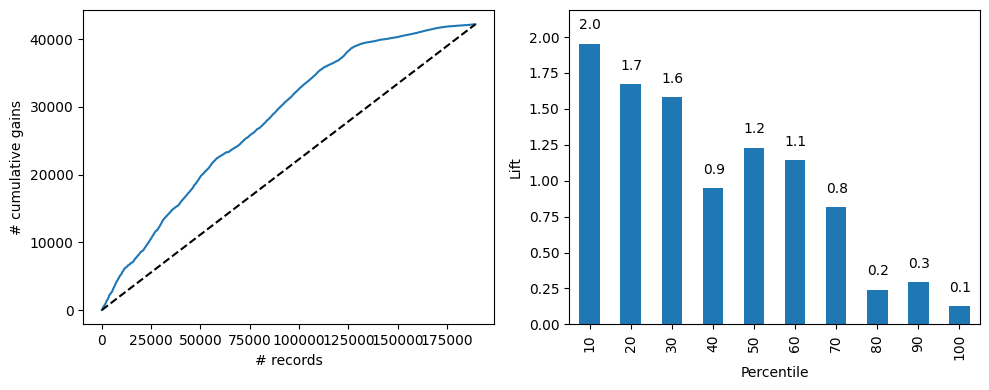

In [ ]:
# Gains and lift charts

predictions = model.predict(valid_X)
predictions_nominal = [0 if x < 0.5 else 1 for x in predictions]

logit_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': 1 - predictions,
    'p(1)': predictions,
    'predicted': predictions_nominal
})

df = logit_result.sort_values(by=['p(1)'], ascending=False)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(df.actual, ax=axes[0])
liftChart(df.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()


Overall the model predicts 2.0 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:

# Get predicted probabilities for the positive class (1: "Default")
pred_prob = model.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")



Best Threshold: 0.24
Maximum Net Profit: 978,117,976.10 USD


#### Option 2 - Stats: model sm.GLM

In [ ]:
# Using stats GLM
logit_reg2 = sm.GLM(train_y, train_X, family = sm.families.Binomial())
logit_result2 = logit_reg2.fit()
print(logit_result2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             MIS_Status   No. Observations:               284117
Model:                            GLM   Df Residuals:                   284109
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.3334e+05
Date:                Sun, 24 Nov 2024   Deviance:                   2.6667e+05
Time:                        21:20:52   Pearson chi2:                 3.08e+05
No. Iterations:                     7   Pseudo R-squ. (CS):             0.1106
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -3.8997      0.03

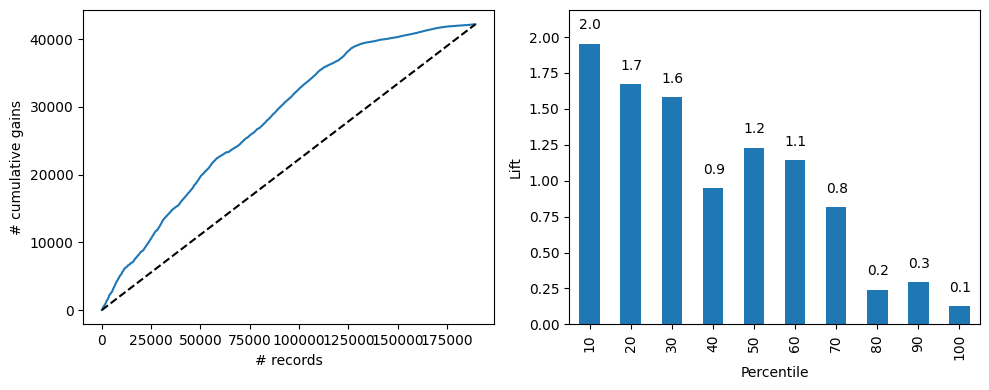

In [ ]:
# Gains and lift charts
predictions = logit_result2.predict(valid_X)
predictions_nominal = [0 if x < 0.5 else 1 for x in predictions]

logit_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': 1 - predictions,
    'p(1)': predictions,
    'predicted': predictions_nominal
})

df = logit_result.sort_values(by=['p(1)'], ascending=False)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(df.actual, ax=axes[0])
liftChart(df.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()


Overall the model predicts 2.0 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:
# Confusion Matrix
# Ensure valid_y contains both 0 and 1
valid_y = np.array(valid_y)  # Convert to a NumPy array if it's not already
all_classes = [0, 1]

# Create confusion matrix with fixed categories
confusion_matrix = pd.crosstab(
    pd.Categorical(valid_y, categories=all_classes),
    pd.Categorical(predictions_nominal, categories=all_classes),
    rownames=['Actual'],
    colnames=['Predicted'],
    dropna=False
)

# Calculate accuracy
accuracy = metrics.accuracy_score(valid_y, predictions_nominal)
print('Accuracy: ', accuracy)

# Display confusion matrix
confusion_matrix


Accuracy:  0.7772422021835997


Predicted,0,1
Actual,,
0,147219,0
1,42193,0


In [ ]:
# The confusion-matrix metrices

# Convert continuous predictions to binary
y_pred = logit_result2.predict(valid_X)
predictions_nominal = [0 if x < 0.5 else 1 for x in y_pred]  # Threshold at 0.5

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, predictions_nominal, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, predictions_nominal, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, predictions_nominal, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, predictions_nominal)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Create scores DataFrame
scores = pd.DataFrame({
    'Model': ['Logistic Regression using stats model sm'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

# Display scores
scores


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression using stats model sm,0.0,0.0,0.0,1.0


In [ ]:
# Net profit for GLM model

# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_result2.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")



Best Threshold: 0.24
Maximum Net Profit: 978,117,976.10 USD


### Logistic Regression using Ridge

#### Option 1 - Ridge: Using liblinear solver

In [ ]:

# Add a constant to the dataset
SBA_df5 = SBA_df3.copy()

# Define features (X) and target variable (y)
y = SBA_df5['MIS_Status']
X = SBA_df5.drop(columns=['MIS_Status'])

# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Create a weights column for the training and validation response variables
train_weights = train_y.map(class_weights)
valid_weights = valid_y.map(class_weights)

# Initialize and fit the logistic regression model with weights
logit_reg = LogisticRegression(penalty="l2", C=1e42, solver='liblinear')
logit_reg.fit(train_X, train_y, sample_weight=train_weights)

# Calculate and print the intercept and coefficients
print('Intercept:', logit_reg.intercept_[0])
print(pd.DataFrame({'Coeff': logit_reg.coef_[0]}, index=train_X.columns).transpose())

# Define a function to calculate AIC
def calculate_aic(y_true, y_pred_proba, num_params):
    """
    Calculate the Akaike Information Criterion (AIC).
    AIC = 2k - 2ln(L), where:
    - k is the number of parameters
    - L is the likelihood of the model
    """
    log_likelihood = -log_loss(y_true, y_pred_proba, normalize=False)
    return 2 * num_params - 2 * log_likelihood

# Predict probabilities for the validation set
valid_pred_proba = logit_reg.predict_proba(valid_X)[:, 1]

# Calculate AIC
num_params = train_X.shape[1] + 1  # Number of predictors + intercept
aic = calculate_aic(valid_y, valid_pred_proba, num_params)

print('AIC:', aic)


Intercept: 8.698232930290667e-10
       DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2   RevLineCr_1  \
Coeff           0.000004 -0.000007  1.109387e-09  9.851750e-11  5.530127e-10   

       Below_10_years   Recession_1  
Coeff    1.054113e-09  6.634117e-10  
AIC: 255283.37215793892


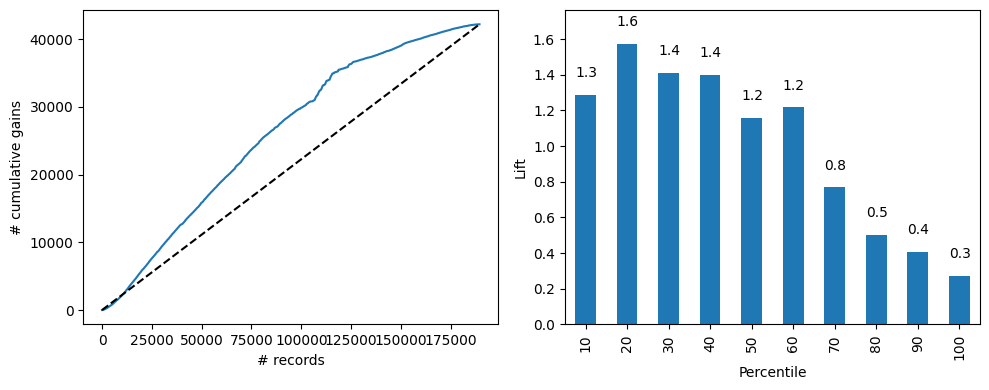

In [ ]:
# Gains and lift chart
logit_reg_pred = logit_reg.predict_proba(valid_X)
full_result = pd.DataFrame({'actual': valid_y,
                            'p(0)': [p[0] for p in logit_reg_pred],
                            'p(1)': [p[1] for p in logit_reg_pred],
                            'predicted': logit_reg.predict(valid_X)})
full_result = full_result.sort_values(by=['p(1)'], ascending=False)

# plot gains and lift charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(full_result.actual, ax=axes[0])
liftChart(full_result.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()

Overall the model predicts 1.3 times better in the first decile. The next 20-60% bars also predict better than a random 10% of samples from the data.

In [ ]:
# Confusion matrix
classificationSummary(full_result.actual, full_result.predicted)


Confusion Matrix (Accuracy 0.5428)

       Prediction
Actual     0     1
     0 71868 75351
     1 11255 30938


In [ ]:
# Computing various metrices

# Assume full_result contains 'actual' and 'predicted'
def compute_metrics(model_name, actual, predicted):
    # Generate confusion matrix
    cm = metrics.confusion_matrix(actual, predicted)
    TN, FP, FN, TP = cm.ravel()  # Unpack confusion matrix values

    # Calculate metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Create a DataFrame for scores
    scores = pd.DataFrame({
        'Model': [model_name],
        'Precision': [precision],
        'Recall': [recall],
        'F1 Score': [f1_score],
        'Specificity': [specificity]
    })

    return scores

# Example usage with full_result DataFrame
model_name = "Logistic Regression with 'liblinear' Solver l2"
metrics_df = compute_metrics(model_name, full_result.actual, full_result.predicted)

# Display scores
metrics_df



,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression with 'liblinear' Solver l2,0.291074,0.73325,0.416724,0.488171


In [ ]:
# Net profit
# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_reg.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")



Best Threshold: 0.01
Maximum Net Profit: 789,042,887.55 USD


#### Option 2 - Ridge: Using the "lbfgs' Solver

In [ ]:
# Add a constant to the dataset
SBA_df6 = SBA_df3.copy()

# Define features (X) and target variable (y)
y = SBA_df6['MIS_Status']
X = SBA_df6.drop(columns=['MIS_Status'])

# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Create a weights column for the training and validation response variables
train_weights = train_y.map(class_weights)
valid_weights = valid_y.map(class_weights)

# Initialize and fit the logistic regression model with weights
logit_reg2 = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    tol=1e-28,
    max_iter=10000,
    random_state=1
)
logit_reg2.fit(train_X, train_y, sample_weight=train_weights)

# Calculate and print the intercept and coefficients
print('Intercept:', logit_reg2.intercept_[0])
print(pd.DataFrame({'Coeff': logit_reg.coef_[0]}, index=train_X.columns).transpose())

# Define a function to calculate AIC
def calculate_aic(y_true, y_pred_proba, num_params):
    """
    Calculate the Akaike Information Criterion (AIC).
    AIC = 2k - 2ln(L), where:
    - k is the number of parameters
    - L is the likelihood of the model
    """
    log_likelihood = -log_loss(y_true, y_pred_proba, normalize=False)
    return 2 * num_params - 2 * log_likelihood

# Predict probabilities for the validation set
valid_pred_proba = logit_reg2.predict_proba(valid_X)[:, 1]

# Calculate AIC
num_params = train_X.shape[1] + 1  # Number of predictors + intercept
aic = calculate_aic(valid_y, valid_pred_proba, num_params)

print('AIC:', aic)


Intercept: -2.168039790746423
       DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2   RevLineCr_1  \
Coeff           0.000004 -0.000007  1.109387e-09  9.851750e-11  5.530127e-10   

       Below_10_years   Recession_1  
Coeff    1.054113e-09  6.634117e-10  
AIC: 267872.76563419146


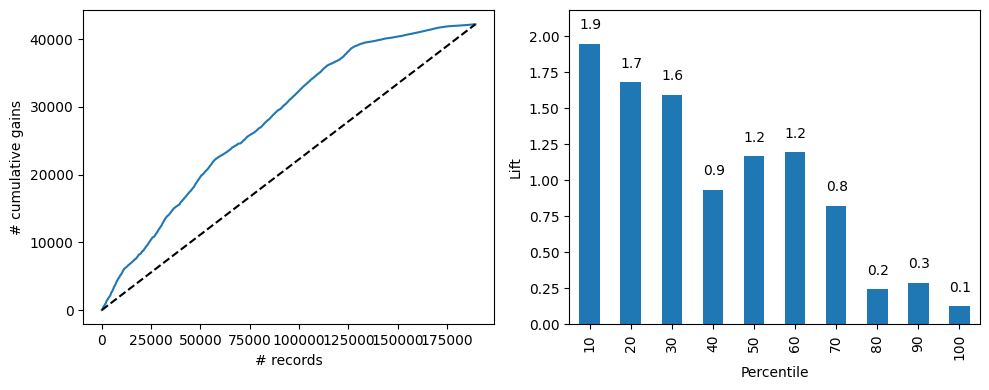

In [ ]:
# Gains and lift chart
logit_reg_pred2 = logit_reg2.predict_proba(valid_X)
full_result = pd.DataFrame({'actual': valid_y,
                            'p(0)': [p[0] for p in logit_reg_pred2],
                            'p(1)': [p[1] for p in logit_reg_pred2],
                            'predicted': logit_reg2.predict(valid_X)})
full_result2 = full_result.sort_values(by=['p(1)'], ascending=False)

# Plot gains and lift chart
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(full_result2.actual, ax=axes[0])
liftChart(full_result2.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()

Overall the model predicts 1.9 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:
# confusion matrix
classificationSummary(full_result2.actual, full_result2.predicted)

Confusion Matrix (Accuracy 0.5029)

       Prediction
Actual     0     1
     0 56069 91150
     1  3001 39192


In [ ]:
# Computing various metrices

# Assume full_result contains 'actual' and 'predicted'
def compute_metrics(model_name, actual, predicted):
    # Generate confusion matrix
    cm = metrics.confusion_matrix(actual, predicted)
    TN, FP, FN, TP = cm.ravel()  # Unpack confusion matrix values

    # Calculate metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Create a DataFrame for scores
    scores = pd.DataFrame({
        'Model': [model_name],
        'Precision': [precision],
        'Recall': [recall],
        'F1 Score': [f1_score],
        'Specificity': [specificity]
    })

    return scores

# Example usage with full_result DataFrame
model_name = "Logistic Regression with 'lbfgs' Solver l2"
metrics_df = compute_metrics(model_name, full_result2.actual, full_result.predicted)

# Display scores
metrics_df



,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression with 'lbfgs' Solver l2,0.2222,0.686417,0.335723,0.311366


In [ ]:
# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_reg2.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")


Best Threshold: 0.01
Maximum Net Profit: 934,242,752.20 USD


#### Option 3 - Ridge: Logistic regression with 'liblinear' Solver 2

In [ ]:

# Add a constant to the dataset (optional for scikit-learn models)
SBA_df7= SBA_df3.copy()

# Define features (X) and target variable (y)
y = SBA_df7['MIS_Status']
X = SBA_df7.drop(columns=['MIS_Status'])

# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Map class weights to the training and validation responses
train_weights = train_y.map(class_weights)

# Initialize and fit the logistic regression model with weights
logit_reg3 = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    tol=1e-28,
    max_iter=10000,
    random_state=1
)
logit_reg3.fit(train_X, train_y, sample_weight=train_weights)

# Calculate and print the intercept and coefficients
print('Intercept:', logit_reg3.intercept_[0])
print(pd.DataFrame({'Coeff': logit_reg.coef_[0]}, index=train_X.columns).transpose())

# Define a function to calculate AIC
def calculate_aic(y_true, y_pred_proba, num_params):
    """
    Calculate the Akaike Information Criterion (AIC).
    AIC = 2k - 2ln(L), where:
    - k is the number of parameters
    - L is the likelihood of the model
    """
    log_likelihood = -log_loss(y_true, y_pred_proba, normalize=False)
    return 2 * num_params - 2 * log_likelihood

# Predict probabilities for the validation set
valid_pred_proba = logit_reg3.predict_proba(valid_X)[:, 1]

# Calculate AIC
num_params = train_X.shape[1] + 1  # Number of predictors + intercept
aic = calculate_aic(valid_y, valid_pred_proba, num_params)

print('AIC:', aic)


Intercept: -2.329196747558477
       DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2   RevLineCr_1  \
Coeff           0.000004 -0.000007  1.109387e-09  9.851750e-11  5.530127e-10   

       Below_10_years   Recession_1  
Coeff    1.054113e-09  6.634117e-10  
AIC: 266976.59519199614


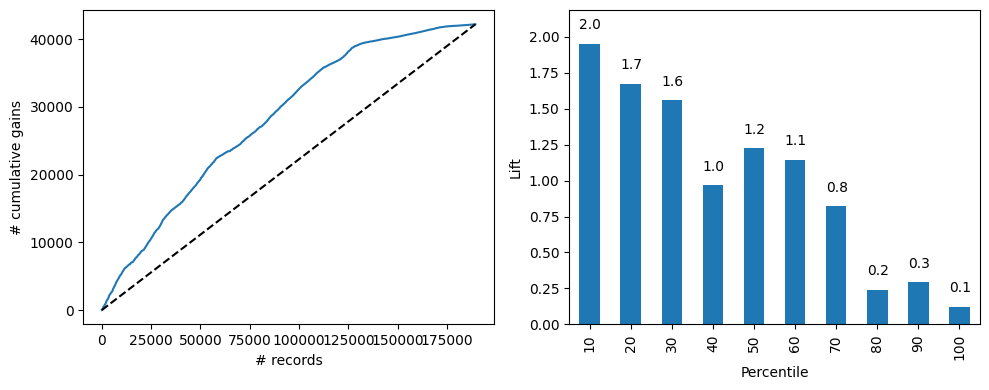

In [ ]:
# Gains and lift chart
logit_reg_pred3 = logit_reg3.predict_proba(valid_X)
full_result = pd.DataFrame({'actual': valid_y,
                            'p(0)': [p[0] for p in logit_reg_pred3],
                            'p(1)': [p[1] for p in logit_reg_pred3],
                            'predicted': logit_reg3.predict(valid_X)})
full_result3 = full_result.sort_values(by=['p(1)'], ascending=False)

# Plot gains and lift charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(full_result3.actual, ax=axes[0])
liftChart(full_result3.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()

Overall the model predicts 2.0 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:
# confusion matrix
classificationSummary(full_result3.actual, full_result3.predicted)

Confusion Matrix (Accuracy 0.5036)

       Prediction
Actual     0     1
     0 56210 91009
     1  3014 39179


In [ ]:
# Computing various metrices

# Assume full_result contains 'actual' and 'predicted'
def compute_metrics(model_name, actual, predicted):
    # Generate confusion matrix
    cm = metrics.confusion_matrix(actual, predicted)
    TN, FP, FN, TP = cm.ravel()  # Unpack confusion matrix values

    # Calculate metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Create a DataFrame for scores
    scores = pd.DataFrame({
        'Model': [model_name],
        'Precision': [precision],
        'Recall': [recall],
        'F1 Score': [f1_score],
        'Specificity': [specificity]
    })

    return scores

# Example usage with full_result DataFrame
model_name = "Logistic Regression with 'liblinear' Solver l2 - 2"
metrics_df = compute_metrics(model_name, full_result3.actual, full_result3.predicted)

# Display scores
metrics_df


,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression with 'liblinear' Solver l2...,0.300942,0.928566,0.454563,0.381812


In [ ]:
# Net profit
# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_reg3.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")



Best Threshold: 0.01
Maximum Net Profit: 935,193,158.90 USD


# Lasso Logistic Regression

#### Option 1 - Lasso: Logistic Regression using saga solver

In [ ]:
SBA_df11 = SBA_df3.copy()

# Define features (X) and target variable (y)
y = SBA_df11['MIS_Status']
X = SBA_df11.drop(columns=['MIS_Status'])

# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Map class weights to the training responses
train_weights = train_y.map(class_weights)


# Initiate scaler
sc = StandardScaler()
# Standardize the training dataset
X_train_transformed = pd.DataFrame(sc.fit_transform(train_X),index=train_X.index, columns=train_X.columns)
# Standardized the testing dataset
X_valid_transformed = pd.DataFrame(sc.transform(valid_X),index=valid_X.index, columns=valid_X.columns)

logit_reg_L1 = LogisticRegressionCV(penalty='l1',  solver='saga', cv=10, random_state=1, Cs=20, max_iter=10000)
logit_reg_L1.fit(X_train_transformed, train_y)

print('intercept ', logit_reg_L1.intercept_[0])
print(pd.DataFrame({'coeff': logit_reg_L1.coef_[0]}, index=X.columns).transpose())
print()
print('AIC', AIC_score(valid_y, logit_reg_L1.predict(valid_X), df = len(train_X.columns) + 1))

intercept  -1.3110892801509997
       DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2  RevLineCr_1  \
coeff                0.0 -0.049917      0.259622           0.0          0.0   

       Below_10_years  Recession_1  
coeff        0.196851     0.126169  

AIC 253111.61380372802


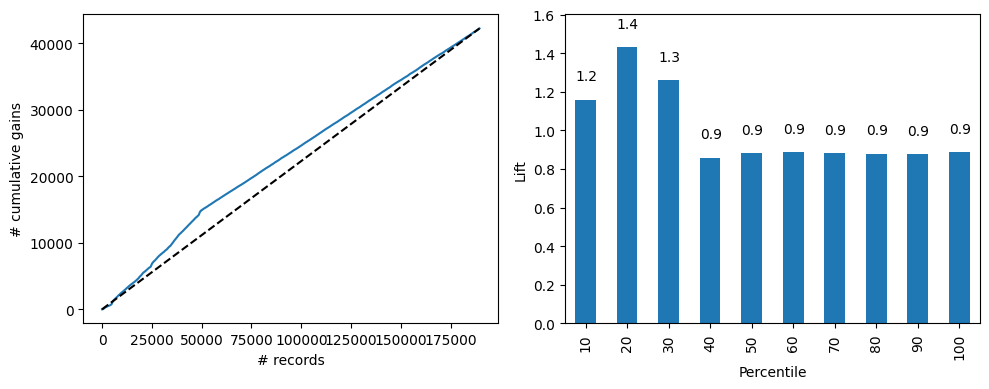

In [ ]:
# Gains and lift chart
logit_reg_pred = logit_reg_L1.predict_proba(valid_X)
full_result = pd.DataFrame({'actual': valid_y,
                            'p(0)': [p[0] for p in logit_reg_pred],
                            'p(1)': [p[1] for p in logit_reg_pred],
                            'predicted': logit_reg_L1.predict(valid_X)})
lasso_full_result1 = full_result.sort_values(by=['p(1)'], ascending=False)


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(lasso_full_result1.actual, ax=axes[0])
liftChart(lasso_full_result1.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()

Overall the model predicts 1.2 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:
# confusion matrix
classificationSummary(lasso_full_result1.actual, lasso_full_result1.predicted)

Confusion Matrix (Accuracy 0.7772)

       Prediction
Actual      0      1
     0 147219      0
     1  42193      0


In [ ]:
# Computing various metrices

# Assume full_result contains 'actual' and 'predicted'
def compute_metrics(model_name, actual, predicted):
    # Generate confusion matrix
    cm = metrics.confusion_matrix(actual, predicted)
    TN, FP, FN, TP = cm.ravel()  # Unpack confusion matrix values

    # Calculate metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Create a DataFrame for scores
    scores = pd.DataFrame({
        'Model': [model_name],
        'Precision': [precision],
        'Recall': [recall],
        'F1 Score': [f1_score],
        'Specificity': [specificity]
    })

    return scores

# Example usage with full_result DataFrame
model_name = "Logistic Regression with 'saga' Solver l1"
metrics_df = compute_metrics(model_name, lasso_full_result1.actual, lasso_full_result1.predicted)

# Display scores
metrics_df

,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression with 'saga' Solver l1,0,0.0,0,1.0


In [ ]:
# Net profit
# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_reg_L1.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")



Best Threshold: 0.01
Maximum Net Profit: 479,500,604.65 USD


#### Option 2 - Lasso: Logistic Regression using liblinear solver

In [ ]:
SBA_df12 = SBA_df3.copy()

# Define features (X) and target variable (y)
y = SBA_df12['MIS_Status']
X = SBA_df12.drop(columns=['MIS_Status'])

In [ ]:
# Define custom weights (1:5 ratio for non-default to default)
class_weights = {1: 5, 0: 1}

# Step 2: Split data into training and validation datasets
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

# Map class weights to the training responses
train_weights = train_y.map(class_weights)

In [ ]:
# Initiate scaler
sc = StandardScaler()
# Standardize the training dataset
X_train_transformed = pd.DataFrame(sc.fit_transform(train_X),index=train_X.index, columns=train_X.columns)
# Standardized the testing dataset
X_valid_transformed = pd.DataFrame(sc.transform(valid_X),index=valid_X.index, columns=valid_X.columns)

In [ ]:
logit_reg_L2 = LogisticRegressionCV(penalty="l1", solver='liblinear', cv=10, random_state=1, Cs=100, tol=1e-8, max_iter=10000)
logit_reg_L2.fit(X_train_transformed, train_y)

print('intercept ', logit_reg_L2.intercept_[0])
print(pd.DataFrame({'coeff': logit_reg_L2.coef_[0]}, index=X.columns).transpose())
print()
print('AIC', AIC_score(valid_y, logit_reg_L2.predict(valid_X), df = len(train_X.columns) + 1))

intercept  -1.1014928601261993
       DisbursementGross  SBA_Appv  UrbanRural_1  UrbanRural_2  RevLineCr_1  \
coeff                0.0 -0.044863      0.230668           0.0          0.0   

       Below_10_years  Recession_1  
coeff        0.166798     0.115235  

AIC 253111.61380372802


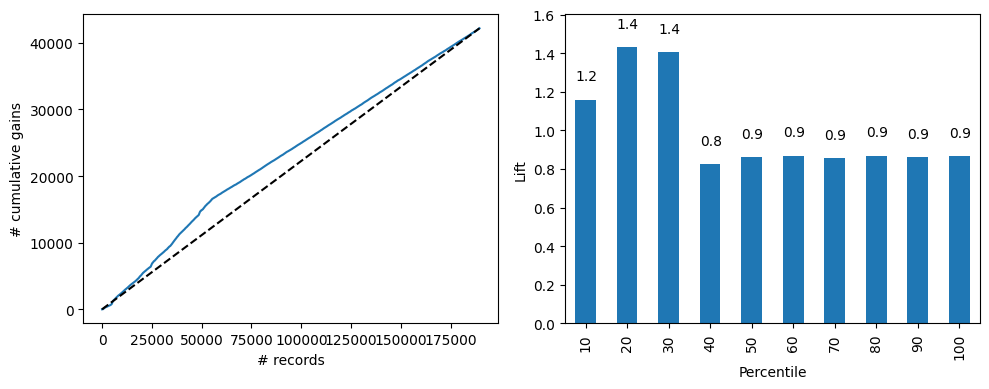

In [ ]:
# Gains and lift chart
logit_reg_pred = logit_reg_L2.predict_proba(valid_X)
full_result = pd.DataFrame({'actual': valid_y,
                            'p(0)': [p[0] for p in logit_reg_pred],
                            'p(1)': [p[1] for p in logit_reg_pred],
                            'predicted': logit_reg_L2.predict(valid_X)})
lasso_full_result2 = full_result.sort_values(by=['p(1)'], ascending=False)


# Plot gains and lift charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(lasso_full_result2.actual, ax=axes[0])
liftChart(lasso_full_result2.actual, title=False, ax=axes[1])

plt.tight_layout()
plt.show()

Overall the model predicts 1.2 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

In [ ]:
# confusion matrix
classificationSummary(lasso_full_result2.actual, lasso_full_result2.predicted)

Confusion Matrix (Accuracy 0.7772)

       Prediction
Actual      0      1
     0 147219      0
     1  42193      0


In [ ]:
# Computing various metrices

# Assume full_result contains 'actual' and 'predicted'
def compute_metrics(model_name, actual, predicted):
    # Generate confusion matrix
    cm = metrics.confusion_matrix(actual, predicted)
    TN, FP, FN, TP = cm.ravel()  # Unpack confusion matrix values

    # Calculate metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Create a DataFrame for scores
    scores = pd.DataFrame({
        'Model': [model_name],
        'Precision': [precision],
        'Recall': [recall],
        'F1 Score': [f1_score],
        'Specificity': [specificity]
    })

    return scores

# Example usage with full_result DataFrame
model_name = "Logistic Regression with 'liblinear' Solver l1"
metrics_df = compute_metrics(model_name, lasso_full_result2.actual, lasso_full_result2.predicted)

# Display scores
metrics_df

,Model,Precision,Recall,F1 Score,Specificity
0,Logistic Regression with 'liblinear' Solver l1,0,0.0,0,1.0


In [ ]:
# Get predicted probabilities for the positive class (1: "Default")
pred_prob = logit_reg_L2.predict(train_X) # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Convert actual_y to numpy array
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Initialize net_profit array for this threshold
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")


Best Threshold: 0.01
Maximum Net Profit: 479,500,604.65 USD


After running the various models, we looked for the model with the best recall and the model with the biggest maximum net profit.

The Logistics stats smf.glm and Logistics stats sm.GLM yielded the the most net profit with $978,117,976.10.

The Logistic Regression Ridge model3 had the best recall score.

The Logistic Regression Ridge model3 had the best F1 score.